# Experiment 2 - Grokking

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

import matplotlib.pyplot as plt
from tqdm import tqdm

## Configuration and Hyperparameters

In [2]:
SEED = 42
TRAIN_SIZE = 1000
BATCH_SIZE = 200
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.01
INIT_SCALE = 8.0
STEPS = 1000000
LOG_INTERVAL = 1000

torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running on device: {device}")

Running on device: cuda


## MNIST Dataset

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

full_train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Subsample training set to 1,000 examples
train_subset = Subset(full_train_dataset, range(TRAIN_SIZE))

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

## MLP Architecture with Scaled Initialization

In [4]:
class GrokkingMLP(nn.Module):
    def __init__(self, init_scale=8.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 200),
            nn.ReLU(),
            nn.Linear(200, 200),
            nn.ReLU(),
            nn.Linear(200, 10)
        )
        # Scale initial weights to induce initial memorization
        with torch.no_grad():
            for param in self.parameters():
                param.mul_(init_scale)

    def forward(self, x):
        return self.net(x)

model = GrokkingMLP(init_scale=INIT_SCALE).to(device)
optimizer = torch.optim.AdamW(
    model.parameters(), 
    lr=LEARNING_RATE, 
    weight_decay=WEIGHT_DECAY
)
criterion = nn.MSELoss()

## Helper Functions

In [5]:
@torch.no_grad()
def evaluate(loader):
    model.eval()
    
    correct = 0
    total = 0
    total_loss = 0.0

    for x_eval, y_eval in loader:
        x_eval, y_eval = x_eval.to(device), y_eval.to(device)
        output_eval = model(x_eval)

        # Compute total_loss for mean MSE loss
        y_eval_ohe = F.one_hot(y_eval, num_classes=10).float()
        loss = criterion(output_eval, y_eval_ohe)
        total_loss += loss.item() * y_eval.size(0)

        # Compute correct predictions
        preds = output_eval.argmax(dim=1)
        correct += (preds == y_eval).sum().item()

        # Compute number of samples
        total += y_eval.size(0)

        # Compute accuracy and mean MSE loss
        accuracy = correct / total
        mean_mse_loss = total_loss / total

    return accuracy, mean_mse_loss

## Training the Model

In [6]:
history = {
    "steps": [], 
    "train_accuracies": [], 
    "test_accuracies": [],
    "train_mse_losses": [],
    "test_mse_losses": []
}
train_iterator = iter(train_loader)

print("Starting Training...")

for step in tqdm(range(STEPS), desc='Progress'):
    try:
        x_train, y_train = next(train_iterator)
    except StopIteration:
        train_iterator = iter(train_loader)
        x_train, y_train = next(train_iterator)

    model.train()
    x_train, y_train = x_train.to(device), y_train.to(device)
    y_train_ohe = F.one_hot(y_train, num_classes=10).float()

    optimizer.zero_grad()
    output_train = model(x_train)
    loss = criterion(output_train, y_train_ohe)
    loss.backward()
    optimizer.step()

    # Log metrics periodically
    if step % LOG_INTERVAL == 0:
        train_accuracy, train_mse_loss = evaluate(train_loader)
        test_accuracy, test_mse_loss = evaluate(test_loader)

        history["steps"].append(step)
        history["train_accuracies"].append(train_accuracy)
        history["test_accuracies"].append(test_accuracy)
        history["train_mse_losses"].append(train_mse_loss)
        history["test_mse_losses"].append(test_mse_loss)

        #print(f"Step {step:5d} | Train Accuracy: {train_accuracy:.4f} | Test Accuracy: {test_accuracy:.4f} | Train MSE Loss: {train_mse_loss:3.4f} | Test MSE Loss: {test_mse_loss:3.4f}")

Starting Training...


Progress: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100000/100000 [17:34<00:00, 94.86it/s]


## Evaluating the Model

### Confusion Matrix

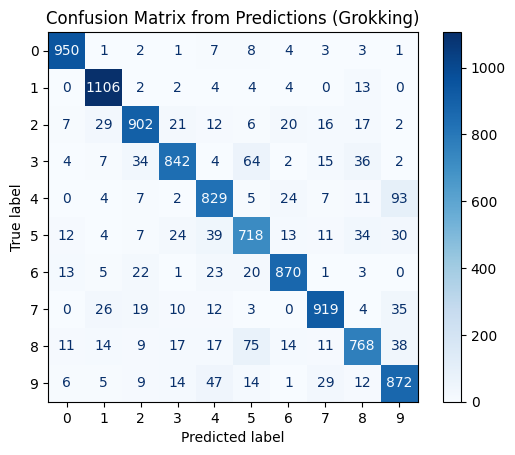

<Figure size 640x480 with 0 Axes>

In [7]:
from utils import display_confusion_matrix

model.eval()
predictions = []
actuals = []
    
for x_test, y_test in test_loader:
    x_test = x_test.to(device)
    prediction = model(x_test).argmax(dim=1)

    predictions += prediction.cpu().tolist()
    actuals += y_test.tolist()

display_confusion_matrix(actuals, predictions, title='Confusion Matrix from Predictions (Grokking)')

### Weight Analysis

Layer: net.1.weight | Shape: torch.Size([200, 784])


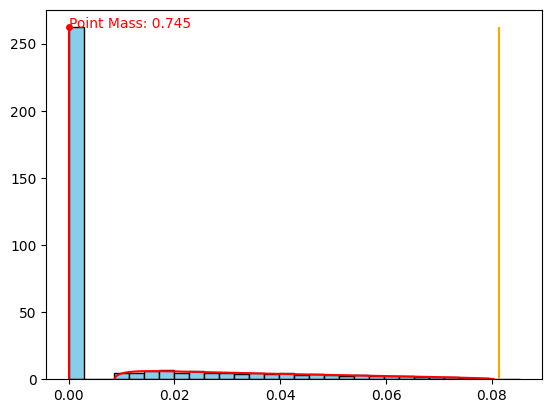

Layer: net.3.weight | Shape: torch.Size([200, 200])


/home/xnell90/projects/rmt/utils.py:22: RuntimeWarning: invalid value encountered in divide
  y_values = q * np.sqrt((a_plus - x_values) * (x_values - a_minus)) / (2 * np.pi * sigma_squared * x_values)


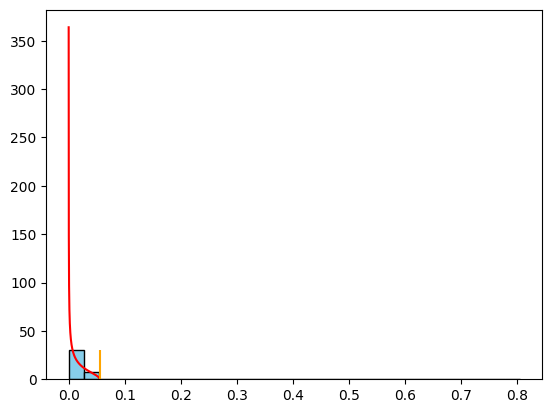

Layer: net.5.weight | Shape: torch.Size([10, 200])


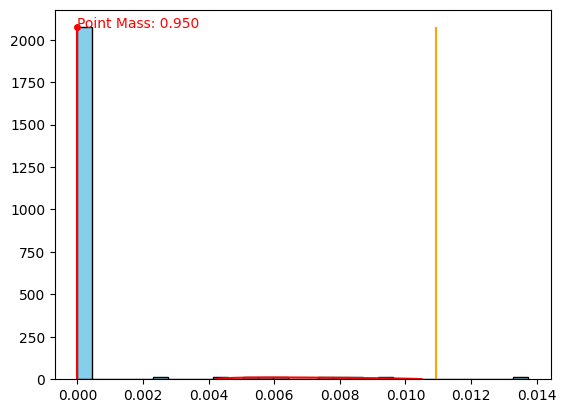

<Figure size 640x480 with 0 Axes>

In [8]:
from utils import analyze_weight_matrices

analyze_weight_matrices(model)